In [1]:
import gc
import pickle
import shutil
import subprocess
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat, savemat
from probeinterface import Probe
import spikeinterface as si
import spikeinterface.preprocessing as spre
import spikeinterface.extractors as se
import spikeinterface.sorters as ss
import spikeinterface.curation as scur
from spikeinterface.sortingcomponents.motion import interpolate_motion
from spikeinterface.curation import compute_merge_unit_groups
from spikeinterface.exporters import export_to_phy
from spikeinterface.widgets import plot_motion_info
from tqdm import tqdm

import RCP_analysis as rcp
from RCP_analysis.python.functions.config_loading import *

# Setup
GEOM_PATH = rcp.resolve_probe_geom_path(PARAMS, REPO_ROOT, session_key=None)
NPRW_CFG = PARAMS.probes.get("NPRW")
INTAN_STREAM = NPRW_CFG.get("neural_data_stream")
STIM_STREAM = NPRW_CFG.get("stim_data_stream")
RADII = (NPRW_CFG.get("local_radius_inner"), NPRW_CFG.get("local_radius_outer"))
RATES = PARAMS.NPRW_rate_est
ARTRMV_MS_BEFORE = float(RATES.get("remove_ms_before", 20.0))
ARTRMV_TAIL_MS = float(RATES.get("remove_tail_ms_after", 20.0))

global_job_kwargs = dict(n_jobs=PARAMS.parallel_jobs, chunk_duration=PARAMS.chunk, progress_bar=True)
si.set_global_job_kwargs(**global_job_kwargs)

BLANKED_DIR = OUT_BASE / "checkpoints" / "NPRW_blanked_sessions"
BLANKED_DIR.mkdir(parents=True, exist_ok=True)

n_channels = 128
fs = 30000.0

# Load probe geometry
mat_probe = loadmat(Path(GEOM_PATH))
intan_geom = {"x": mat_probe["xcoords"].ravel(), "y": mat_probe["ycoords"].ravel()}
assert intan_geom["x"].size == intan_geom["y"].size
if "chanMap0ind" not in mat_probe:
    raise ValueError("No 0-based chanmap in .mat geometry file.")
intan_probe_mapping = mat_probe["chanMap0ind"].ravel()
if intan_probe_mapping.size != intan_geom["x"].size:
    raise ValueError("device_index_0based length != #contacts")

nprw_probe = Probe(ndim=2)
nprw_probe.set_contacts(
    positions=np.c_[intan_geom["x"], intan_geom["y"]],
    shapes="square", shape_params={"width": 12.0},
)
nprw_probe.set_device_channel_indices(intan_probe_mapping)


old (blank after interp): 212 units
new (blank before motion): 190 units

36/212 old units matched
154/190 new units unmatched


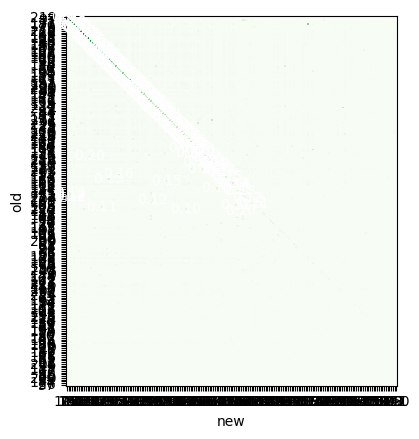

In [2]:
from spikeinterface import load_sorting_analyzer
import spikeinterface.comparison as scmp
import spikeinterface.widgets as sw

SORT_CKPT = OUT_BASE / "checkpoints" / "sorting_results" / "BL_closed_loop_STIM_003_250528_143802_blanking"

sorting_old = load_sorting_analyzer(SORT_CKPT / "analyzer_blanking").sorting
sorting_new = load_sorting_analyzer(SORT_CKPT / "analyzer_pre_slay").sorting

print(f"old (blank after interp): {sorting_old.get_num_units()} units")
print(f"new (blank before motion): {sorting_new.get_num_units()} units")

cmp = scmp.compare_two_sorters(
    sorting1=sorting_old,
    sorting2=sorting_new,
    sorting1_name="old",
    sorting2_name="new",
)

%matplotlib inline
sw.plot_agreement_matrix(sorting_comparison=cmp)

old_to_new, new_to_old = cmp.get_matching()
n_matched = (old_to_new != -1).sum()
print(f"\n{n_matched}/{len(old_to_new)} old units matched")
print(f"{(new_to_old == -1).sum()}/{len(new_to_old)} new units unmatched")